<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/13_Introducing_Automatic_Optimization_Framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 13 — Introducing Automatic Optimization: Let's Build a Deep Learning Framework

**Grokking Deep Learning** (Andrew W. Trask) — Tugas 2: *Code Reproduction + Theoretical Deep-Dive*

Pada bab-bab sebelumnya, setiap *backpropagation* ditulis tangan. Itu rawan salah dan tidak skalabel. Bab ini membangun **framework deep learning mini** (mirip PyTorch/TensorFlow) dari nol: tensor dengan **autograd** (diferensiasi otomatis), layer, optimizer, fungsi loss, embedding, dan RNN layer.

**Isi notebook:**
1. Apa itu framework? *Tensor* dan konsep autograd
2. Autograd: *creators*, *creation_op*, grafik komputasi, `backward()`
3. Tensor yang dipakai berkali-kali (penghitungan `children`)
4. Operasi: `add, neg, sub, mul, sum, expand, transpose, mm` + verifikasi gradien numerik
5. Melatih jaringan dengan autograd, lalu `SGD`, `Layer`, `Linear`, `Sequential`, `MSELoss`
6. Layer nonlinearitas (`Tanh`, `Sigmoid`), `Embedding` + `index_select`, `CrossEntropyLoss`
7. `RNNCell` dan melatih RNN dengan framework sendiri
8. Tanya-jawab konsep, latihan mandiri, dan rangkuman

> Seluruh data pada bab ini adalah data mainan yang dibuat di notebook (tidak memerlukan unduhan).

## 1. Tensor dengan autograd

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Tensor(object):
    def __init__(self, data, autograd=False, creators=None, creation_op=None, id=None):
        self.data = np.array(data)
        self.autograd = autograd
        self.grad = None
        self.id = np.random.randint(0, 10**9) if id is None else id
        self.creators = creators
        self.creation_op = creation_op
        self.children = {}
        if creators is not None:
            for c in creators:
                c.children[self.id] = c.children.get(self.id, 0) + 1

    def all_children_grads_accounted_for(self):
        return all(cnt == 0 for cnt in self.children.values())

    def backward(self, grad=None, grad_origin=None):
        if not self.autograd: return
        if grad is None: grad = Tensor(np.ones_like(self.data))
        if grad_origin is not None:
            if self.children[grad_origin.id] == 0:
                raise Exception("cannot backprop more than once")
            self.children[grad_origin.id] -= 1
        self.grad = grad if self.grad is None else Tensor(self.grad.data + grad.data)
        assert grad.autograd == False
        if self.creators is not None and (self.all_children_grads_accounted_for() or grad_origin is None):
            op = self.creation_op; c = self.creators
            if op == "add":
                c[0].backward(self.grad, self); c[1].backward(self.grad, self)
            elif op == "sub":
                c[0].backward(Tensor(self.grad.data), self); c[1].backward(Tensor((-self.grad).data), self)
            elif op == "mul":
                c[0].backward(self.grad * c[1], self); c[1].backward(self.grad * c[0], self)
            elif op == "neg":
                c[0].backward((-self.grad), self)
            elif op == "mm":
                c[0].backward(self.grad.mm(c[1].transpose()), self)
                c[1].backward(self.grad.transpose().mm(c[0]).transpose(), self)
            elif op == "transpose":
                c[0].backward(self.grad.transpose(), self)
            elif op.startswith("sum_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.expand(dim, c[0].data.shape[dim]), self)
            elif op.startswith("expand_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.sum(dim), self)
            elif op == "sigmoid":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (self * (ones - self)), self)
            elif op == "tanh":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (ones - (self * self)), self)
            elif op == "index_select":
                new_grad = np.zeros_like(c[0].data)
                idx = self.index_select_indices.data.flatten()
                g = self.grad.data.reshape(len(idx), -1)
                for i in range(len(idx)): new_grad[idx[i]] += g[i]
                c[0].backward(Tensor(new_grad), self)
            elif op == "cross_entropy":
                dx = (self.softmax_output - self.target_dist) / len(self.target_dist)   # rata-rata atas batch (buku: tanpa pembagian)
                c[0].backward(Tensor(dx), self)

    def _bin(self, other, op, fn):
        if self.autograd and other.autograd:
            return Tensor(fn(self.data, other.data), autograd=True, creators=[self, other], creation_op=op)
        return Tensor(fn(self.data, other.data))
    def __add__(self, other): return self._bin(other, "add", lambda a, b: a + b)
    def __sub__(self, other): return self._bin(other, "sub", lambda a, b: a - b)
    def __mul__(self, other): return self._bin(other, "mul", lambda a, b: a * b)
    def mm(self, x):          return self._bin(x, "mm", lambda a, b: a.dot(b))
    def __neg__(self):
        if self.autograd: return Tensor(self.data * -1, autograd=True, creators=[self], creation_op="neg")
        return Tensor(self.data * -1)
    def sum(self, dim):
        if self.autograd: return Tensor(self.data.sum(dim), autograd=True, creators=[self], creation_op="sum_" + str(dim))
        return Tensor(self.data.sum(dim))
    def expand(self, dim, copies):
        trans_cmd = list(range(0, len(self.data.shape))); trans_cmd.insert(dim, len(self.data.shape))
        new_data = self.data.repeat(copies).reshape(list(self.data.shape) + [copies]).transpose(trans_cmd)
        if self.autograd: return Tensor(new_data, autograd=True, creators=[self], creation_op="expand_" + str(dim))
        return Tensor(new_data)
    def transpose(self):
        if self.autograd: return Tensor(self.data.transpose(), autograd=True, creators=[self], creation_op="transpose")
        return Tensor(self.data.transpose())
    def sigmoid(self):
        if self.autograd: return Tensor(1 / (1 + np.exp(-self.data)), autograd=True, creators=[self], creation_op="sigmoid")
        return Tensor(1 / (1 + np.exp(-self.data)))
    def tanh(self):
        if self.autograd: return Tensor(np.tanh(self.data), autograd=True, creators=[self], creation_op="tanh")
        return Tensor(np.tanh(self.data))
    def index_select(self, indices):
        if self.autograd:
            new = Tensor(self.data[indices.data], autograd=True, creators=[self], creation_op="index_select")
            new.index_select_indices = indices
            return new
        return Tensor(self.data[indices.data])
    def cross_entropy(self, target_indices):
        temp = np.exp(self.data - self.data.max(axis=-1, keepdims=True))
        softmax_output = temp / np.sum(temp, axis=len(self.data.shape) - 1, keepdims=True)
        t = target_indices.data.flatten()
        p = softmax_output.reshape(len(t), -1)
        target_dist = np.eye(p.shape[1])[t]
        loss = -(np.log(p) * target_dist).sum(1).mean()
        if self.autograd:
            out = Tensor(loss, autograd=True, creators=[self], creation_op="cross_entropy")
            out.softmax_output = softmax_output; out.target_dist = target_dist
            return out
        return Tensor(loss)
    def __repr__(self): return str(self.data.__repr__())
    def __str__(self):  return str(self.data.__str__())

a = Tensor([1, 2, 3, 4, 5], autograd=True)
b = Tensor([2, 2, 2, 2, 2], autograd=True)
c = Tensor([5, 4, 3, 2, 1], autograd=True)
d = a + b
e = b + c
f = d + e
f.backward(Tensor(np.array([1, 1, 1, 1, 1])))
print("grad a:", a.grad.data, "| grad b:", b.grad.data, "| grad c:", c.grad.data)
print("(b dipakai di d dan e, sehingga gradiennya 2)")

grad a: [1 1 1 1 1] | grad b: [2 2 2 2 2] | grad c: [1 1 1 1 1]
(b dipakai di d dan e, sehingga gradiennya 2)


**Cara kerja:** setiap operasi menghasilkan tensor baru yang menyimpan `creators` (induk) dan `creation_op` (nama operasi). Ini membentuk **grafik komputasi**. `backward()` menyalurkan gradien ke induknya sesuai aturan tiap operasi. Kamus `children` menghitung berapa kali sebuah tensor dipakai; gradiennya baru diteruskan ke induk setelah **semua anak** menyumbang gradien (kasus tensor yang dipakai berkali-kali).

In [2]:
# Tensor yang dipakai berkali-kali: y = x + x -> dy/dx = 2
x = Tensor([1., 2., 3.], autograd=True)
y = x + x
y.backward(Tensor(np.ones(3)))
print("grad x untuk y = x + x :", x.grad.data)

# Tambahan: backward dua kali harus ditolak
try:
    p = Tensor([1.], autograd=True); q = p + p
    q.backward(Tensor([1.])); q.creators[0].backward(Tensor([1.]), q)
except Exception as ex:
    print("Error yang diharapkan:", ex)

grad x untuk y = x + x : [2. 2. 2.]
Error yang diharapkan: cannot backprop more than once


### Verifikasi gradien dengan *numerical gradient check* (Tambahan)

*(Tambahan, bukan dari buku.)* Kita bandingkan gradien autograd untuk `L = sum( (x·W + bias)·(x·W + bias) )` dengan turunan numerik (selisih terpusat).

In [3]:
rng = np.random.RandomState(0)
X = rng.randn(4, 3); W0 = rng.randn(3, 2); B0 = rng.randn(2)

def forward(Wd, Bd, grad=False):
    x = Tensor(X, autograd=True); W = Tensor(Wd, autograd=True); B = Tensor(Bd, autograd=True)
    h = x.mm(W) + B.expand(0, 4)
    L = (h * h).sum(0).sum(0)
    return L, W, B

L, W, B = forward(W0, B0); L.backward()
num = np.zeros_like(W0); eps = 1e-6
for i in range(W0.shape[0]):
    for j in range(W0.shape[1]):
        Wp = W0.copy(); Wp[i, j] += eps; Wm = W0.copy(); Wm[i, j] -= eps
        num[i, j] = (forward(Wp, B0)[0].data - forward(Wm, B0)[0].data) / (2 * eps)
print("Selisih maksimum gradien W (autograd vs numerik): %.2e" % np.abs(W.grad.data - num).max())
numb = np.zeros_like(B0)
for j in range(len(B0)):
    Bp = B0.copy(); Bp[j] += eps; Bm = B0.copy(); Bm[j] -= eps
    numb[j] = (forward(W0, Bp)[0].data - forward(W0, Bm)[0].data) / (2 * eps)
print("Selisih maksimum gradien bias            : %.2e" % np.abs(B.grad.data - numb).max())

Selisih maksimum gradien W (autograd vs numerik): 3.53e-09
Selisih maksimum gradien bias            : 1.47e-09


## 2. Melatih jaringan dengan autograd dan optimizer `SGD`

Pertama, jaringan dua layer dengan bobot sebagai `Tensor` dan pembaruan manual; lalu `SGD` mengotomatiskan pembaruannya.

In [4]:
np.random.seed(0)
data = Tensor(np.array([[0,0],[0,1],[1,0],[1,1]]), autograd=True)
target = Tensor(np.array([[0],[1],[0],[1]]), autograd=True)
w = [Tensor(np.random.rand(2, 3), autograd=True), Tensor(np.random.rand(3, 1), autograd=True)]
for i in range(10):
    pred = data.mm(w[0]).mm(w[1])
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward(Tensor(np.ones_like(loss.data)))
    for w_ in w:
        w_.data -= w_.grad.data * 0.1
        w_.grad.data *= 0
    if i % 3 == 0 or i == 9: print("iter %d  loss=%.5f" % (i, loss.data[0]))

iter 0  loss=0.58128
iter 3  loss=0.34489
iter 6  loss=0.17539
iter 9  loss=0.06849


In [5]:
class SGD(object):
    def __init__(self, parameters, alpha=0.1):
        self.parameters = parameters; self.alpha = alpha
    def zero(self):
        for p in self.parameters: p.grad.data *= 0
    def step(self, zero=True):
        for p in self.parameters:
            p.data -= p.grad.data * self.alpha
            if zero: p.grad.data *= 0

np.random.seed(0)
w = [Tensor(np.random.rand(2, 3), autograd=True), Tensor(np.random.rand(3, 1), autograd=True)]
optim = SGD(parameters=w, alpha=0.1)
for i in range(10):
    pred = data.mm(w[0]).mm(w[1])
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward(Tensor(np.ones_like(loss.data)))
    optim.step()
print("Loss akhir dengan SGD:", loss.data[0])

Loss akhir dengan SGD: 0.09694015443480727


## 3. Layer, `Linear`, `Sequential`, dan loss

Layer membungkus parameter dan `forward`. `Sequential` menjalankan daftar layer berurutan dan mengumpulkan semua parameter. (`Layer` yang berisi layer lain adalah ide inti framework modern.)

Loss iterasi 0 = 1.7272, iterasi 199 = 0.00069
Prediksi akhir: [0.012 0.986 0.015 0.988] | target: [0 1 0 1]


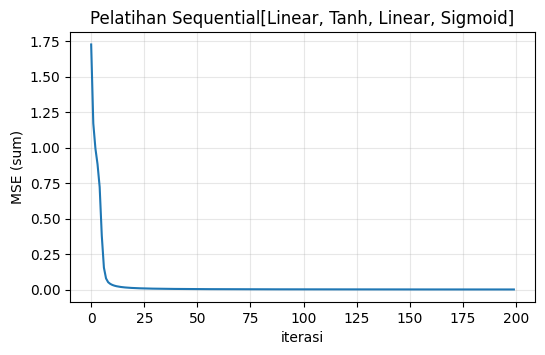

In [6]:
class Layer(object):
    def __init__(self): self.parameters = list()
    def get_parameters(self): return self.parameters

class Linear(Layer):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()
        W = np.random.randn(n_inputs, n_outputs) * np.sqrt(2.0 / n_inputs)
        self.weight = Tensor(W, autograd=True)
        self.bias = Tensor(np.zeros(n_outputs), autograd=True)
        self.parameters += [self.weight, self.bias]
    def forward(self, input):
        return input.mm(self.weight) + self.bias.expand(0, len(input.data))

class Sequential(Layer):
    def __init__(self, layers=list()):
        super().__init__(); self.layers = layers
    def add(self, layer): self.layers.append(layer)
    def forward(self, input):
        for layer in self.layers: input = layer.forward(input)
        return input
    def get_parameters(self):
        params = list()
        for l in self.layers: params += l.get_parameters()
        return params

class MSELoss(Layer):
    def forward(self, pred, target): return ((pred - target) * (pred - target)).sum(0)

class Tanh(Layer):
    def forward(self, input): return input.tanh()
class Sigmoid(Layer):
    def forward(self, input): return input.sigmoid()

np.random.seed(0)
model = Sequential([Linear(2, 3), Tanh(), Linear(3, 1), Sigmoid()])
criterion = MSELoss()
optim = SGD(model.get_parameters(), alpha=1)
losses = []
for i in range(200):
    pred = model.forward(data)
    loss = criterion.forward(pred, target)
    loss.backward(Tensor(np.ones_like(loss.data)))
    optim.step(); losses.append(loss.data[0])
print("Loss iterasi 0 = %.4f, iterasi 199 = %.5f" % (losses[0], losses[-1]))
print("Prediksi akhir:", np.round(model.forward(data).data.flatten(), 3), "| target:", target.data.flatten())
plt.figure(figsize=(6,3.5)); plt.plot(losses); plt.xlabel("iterasi"); plt.ylabel("MSE (sum)"); plt.title("Pelatihan Sequential[Linear, Tanh, Linear, Sigmoid]"); plt.grid(alpha=.3); plt.show()

## 4. `Embedding` dan `CrossEntropyLoss`

`index_select` menyalurkan gradien hanya ke baris yang dipilih (gradien yang dikumpulkan bila indeks berulang). `CrossEntropyLoss` menggabungkan softmax dan *negative log likelihood*, dengan gradien sederhana `softmax − target`.

In [7]:
class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.vocab_size = vocab_size; self.dim = dim
        weight = (np.random.rand(vocab_size, dim) - 0.5) / dim
        self.weight = Tensor(weight, autograd=True)
        self.parameters.append(self.weight)
    def forward(self, input): return self.weight.index_select(input)

class CrossEntropyLoss(object):
    def forward(self, input, target): return input.cross_entropy(target)

np.random.seed(0)
data_i = Tensor(np.array([1, 2, 1, 2]), autograd=True)
target_i = Tensor(np.array([0, 1, 0, 1]), autograd=True)
model = Sequential([Embedding(3, 3), Tanh(), Linear(3, 4)])
criterion = CrossEntropyLoss()
optim = SGD(model.get_parameters(), alpha=0.1)
for i in range(10):
    pred = model.forward(data_i)
    loss = criterion.forward(pred, target_i)
    loss.backward(Tensor(np.ones_like(loss.data)))
    optim.step()
    if i % 3 == 0 or i == 9: print("iter %d  loss=%.4f" % (i, loss.data))

iter 0  loss=1.3885
iter 3  loss=1.0665
iter 6  loss=0.8295
iter 9  loss=0.6582


## 5. `RNNCell`: lapisan rekuren di framework sendiri

`RNNCell` memiliki tiga `Linear`: *input→hidden*, *hidden→hidden* (matriks transisi), dan *hidden→output*. Pada setiap langkah: `hidden_baru = aktivasi(W_ih·x + W_hh·hidden_lama)`, `output = W_ho·hidden_baru`.

Sebagai tugas latihan, kita ajari model memprediksi **kata berikutnya** pada teks sintetis berulang. Ada keambiguan yang hanya bisa dipecahkan dengan **memori**: setelah "to the", tempatnya bergantung pada nama di awal kalimat.

In [8]:
class RNNCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output, activation='sigmoid'):
        super().__init__()
        self.n_inputs, self.n_hidden, self.n_output = n_inputs, n_hidden, n_output
        self.activation = Sigmoid() if activation == 'sigmoid' else Tanh()
        self.w_ih = Linear(n_inputs, n_hidden)
        self.w_hh = Linear(n_hidden, n_hidden)
        self.w_ho = Linear(n_hidden, n_output)
        self.parameters += self.w_ih.get_parameters() + self.w_hh.get_parameters() + self.w_ho.get_parameters()
    def forward(self, input, hidden):
        from_prev_hidden = self.w_hh.forward(hidden)
        combined = self.w_ih.forward(input) + from_prev_hidden
        new_hidden = self.activation.forward(combined)
        output = self.w_ho.forward(new_hidden)
        return output, new_hidden
    def init_hidden(self, batch_size=1):
        return Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)

story = ("mary went to the garden . john went to the kitchen . sandra went to the office . daniel went to the hallway . ").split()
vocab = sorted(set(story)); w2i = {w: i for i, w in enumerate(vocab)}
idx = np.array([w2i[w] for w in story * 6])
bptt = 6
starts = np.arange(0, len(idx) - bptt - 1)
inputs  = np.stack([idx[s:s + bptt] for s in starts])        # (N, bptt)
targets = np.array([idx[s + bptt] for s in starts])           # kata setelah jendela
print("Kosakata:", vocab); print("Jumlah jendela latih:", len(starts), "| panjang jendela:", bptt)

np.random.seed(1)
embed = Embedding(vocab_size=len(vocab), dim=16)
model = RNNCell(n_inputs=16, n_hidden=32, n_output=len(vocab), activation='tanh')
criterion = CrossEntropyLoss()
optim = SGD(parameters=model.get_parameters() + embed.get_parameters(), alpha=0.5)

hist = []
for it in range(150):
    hidden = model.init_hidden(batch_size=len(starts))
    for t in range(bptt):
        x = Tensor(inputs[:, t], autograd=True)
        output, hidden = model.forward(embed.forward(x), hidden)
    loss = criterion.forward(output, Tensor(targets, autograd=True))
    loss.backward(); optim.step()
    hist.append(float(loss.data))
    if it % 30 == 0 or it == 149:
        acc = (output.data.argmax(1) == targets).mean()
        print("iter %3d  loss=%.4f  akurasi next-word=%.3f" % (it, loss.data, acc))

Kosakata: ['.', 'daniel', 'garden', 'hallway', 'john', 'kitchen', 'mary', 'office', 'sandra', 'the', 'to', 'went']
Jumlah jendela latih: 137 | panjang jendela: 6
iter   0  loss=2.5228  akurasi next-word=0.073
iter  30  loss=0.5007  akurasi next-word=0.883
iter  60  loss=0.4586  akurasi next-word=0.883
iter  90  loss=0.4413  akurasi next-word=0.883
iter 120  loss=0.4275  akurasi next-word=0.927
iter 149  loss=0.4145  akurasi next-word=0.927


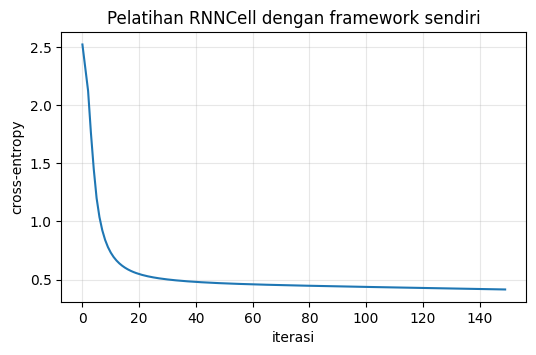

garden . john went to the -> kitchen
kitchen . sandra went to the -> office
office . daniel went to the -> hallway


In [9]:
plt.figure(figsize=(6,3.5)); plt.plot(hist); plt.xlabel("iterasi"); plt.ylabel("cross-entropy"); plt.title("Pelatihan RNNCell dengan framework sendiri"); plt.grid(alpha=.3); plt.show()
# Uji: konteks 6 kata terakhir sebelum tempat, mis. "... john went to the" -> kitchen
def predict_next(words):
    hidden = model.init_hidden(1)
    for w in words:
        output, hidden = model.forward(embed.forward(Tensor(np.array([w2i[w]]), autograd=True)), hidden)
    return vocab[int(output.data.argmax())]
for ctx in (["garden", ".", "john", "went", "to", "the"], ["kitchen", ".", "sandra", "went", "to", "the"], ["office", ".", "daniel", "went", "to", "the"]):
    print(" ".join(ctx), "->", predict_next(ctx))

## 6. Tanya-jawab konsep

**1. Mengapa membangun framework?** Menulis backprop manual lambat dan rawan salah; framework mengotomatiskan gradien, menyediakan layer siap pakai, dan memudahkan eksperimen.

**2. Apa itu autograd?** Setiap operasi tensor mencatat induk dan jenis operasinya sehingga terbentuk grafik komputasi; `backward()` menerapkan aturan rantai di grafik itu dari output ke input.

**3. Mengapa perlu menghitung `children`?** Bila sebuah tensor dipakai lebih dari sekali, gradiennya harus **dijumlahkan** dari semua pemakai sebelum diteruskan ke induk; `children` menjamin urutan ini benar (contoh `x + x` → gradien 2).

**4. Mengapa gradien `sum` adalah `expand` dan sebaliknya?** `sum` memampatkan sebuah dimensi, sehingga gradiennya harus disalin ke semua elemen dimensi itu (`expand`); `expand` menyalin, sehingga gradiennya dijumlahkan (`sum`).

**5. Apa gradien `mm`?** Untuk `C = A·B`: `dA = dC·Bᵀ` dan `dB = Aᵀ·dC`.

**6. Mengapa `cross_entropy` memiliki gradien `softmax − target`?** Turunan gabungan softmax dan NLL menyederhana menjadi selisih distribusi prediksi dan distribusi target. Pada notebook ini gradien dibagi jumlah sampel batch (konsisten dengan loss yang merupakan *rata-rata*); buku tidak membaginya, sehingga learning rate yang cocok berbeda.

**7. Apa bedanya `Layer` dan `Sequential`?** `Layer` adalah blok dengan parameter dan `forward`; `Sequential` adalah layer yang berisi layer lain dan menjalankannya berurutan.

## 7. Latihan mandiri (dengan jawaban)

**Latihan 1.** Berapa gradien `a` pada `f = a*a` untuk `a=3`? **Jawaban:** 6, karena `mul` menjumlahkan dua kontribusi (3 + 3) lewat penghitungan `children`.

**Latihan 2.** Tambahkan aktivasi ReLU. **Jawaban:** `relu(x) = max(x,0)`; gradiennya `grad * (x > 0)`. Tambah `creation_op="relu"` pada `Tensor` dan cabang `backward` yang meneruskan `self.grad * Tensor((c[0].data>0).astype(float))`.

**Latihan 3.** Mengapa `SGD.step` mengosongkan gradien (`zero=True`)? **Jawaban:** `backward` mengakumulasi gradien; tanpa pengosongan, gradien iterasi lama ikut terjumlah.

**Latihan 4.** Berapa parameter `RNNCell(16, 32, 10)`? **Jawaban:** `w_ih`: 16·32+32=544; `w_hh`: 32·32+32=1056; `w_ho`: 32·10+10=330; total **1930**.

## Rangkuman

- **Framework** = tensor + autograd + layer + loss + optimizer; tanpa itu tiap arsitektur baru menuntut backprop manual.
- **Autograd** membangun grafik komputasi (`creators`, `creation_op`) dan memakai aturan rantai; `children` mengatasi tensor yang dipakai berulang. Gradien autograd cocok dengan gradien numerik (selisih ≈ 1e-9 atau lebih kecil, lihat output).
- `Linear`, `Sequential`, `Tanh`, `Sigmoid`, `Embedding`, `MSELoss`, `CrossEntropyLoss`, dan `RNNCell` dibangun di atas autograd yang sama; `SGD` memperbarui parameter.
- RNN dari framework sendiri belajar memprediksi kata berikutnya yang membutuhkan **memori** lintas beberapa langkah.